# Association rule mining: product models bought together
**Topic 3: Product and Association Rules (CompanyX / AdventureWorks)**

Reads shipped-order baskets from the warehouse (`CompanyX_DW`), mines pair rules **{A} → {B}** at **Product Model** level with FP-Growth (`mlxtend`), classifies each rule, and writes the result to `dw.AssociationRulesFact`.

**Method (matches the project design)**
- Input: `dw.OrderLineFact` joined to `dw.ProductDim` (model level) and `dw.CustomerDim` (channel). Only lines with `OrderQty > 0 AND UnitPrice > 0` count as purchases.
- One run per channel: **Individual** (main analysis) and **Reseller** (comparison only). No pooled run.
- Single-model orders **stay in the basket matrix**, so support and lift are divided by all orders of the run, not only by the multi-model ones.
- Pair rules only (`max_len = 2`), because the rules table holds one item on each side.
- Rules below 1% support are not stored. Every stored rule gets one type: `Bundle`, `Hidden gem`, `Chance`, `Substitute` or `Weak` (cutoffs in the config cell, the team's own definitions).
- Association is not causation: rules describe co-occurrence in 2011 to 2014 shipped orders.

**Requirements:** Python 3.9+, `pandas`, `numpy`, `matplotlib`, `sqlalchemy`, `pyodbc`, `mlxtend`, and a SQL Server ODBC driver. Run the cells from top to bottom.

In [15]:
# pip install pandas numpy matplotlib sqlalchemy pyodbc mlxtend
from datetime import datetime
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text
from mlxtend.frequent_patterns import fpgrowth, association_rules

## 1. Configuration

In [16]:
SERVER   = "DESKTOP-LEFTSEP"      # SQL Server instance (the one used in SSMS)
DATABASE = "CompanyX_DW"

CHANNELS    = ["Individual", "Reseller"]          # Individual = main run, Reseller = comparison run
MIN_SUPPORT = {"Individual": 0.01, "Reseller": 0.01}   # rules below 1% support are not stored

# Classification cutoffs (the team's own definitions, to be checked with the lecturer)
LIFT_STRONG     = 1.5      # lift >= 1.5 is a strong association
SUPPORT_BUNDLE  = 0.05     # support >= 5% counts as high support

# Brief's thresholds, used only to flag candidates on screen (not stored)
CROSS_SELL = dict(lift=1.5, support=0.01, confidence=0.40)
BUNDLING   = dict(lift=1.5, support_min=0.01, support_max=0.05, confidence=0.50)  # confidence in at least one direction

KEEP_HISTORY = False       # False: replace the channel's rules on each run; True: keep earlier runs (compare with GeneratedDate)

# Warehouse reconciliation figure for the individual run (orders with 2+ models, shipped, valid lines)
EXPECTED_MULTI_MODEL = {"Individual": 17805}

## 2. Connect to the warehouse

In [17]:
import pyodbc

def pick_driver():
    installed = pyodbc.drivers()
    for name in ("ODBC Driver 18 for SQL Server", "ODBC Driver 17 for SQL Server", "SQL Server"):
        if name in installed:
            return name
    raise RuntimeError(f"No SQL Server ODBC driver found. Installed drivers: {installed}")

DRIVER = pick_driver()
odbc = (f"DRIVER={{{DRIVER}}};SERVER={SERVER};DATABASE={DATABASE};"
        "Trusted_Connection=yes;TrustServerCertificate=yes;")
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc), fast_executemany=True)

with engine.connect() as conn:
    print("Driver:", DRIVER)
    print("Fact lines in warehouse:", conn.execute(text("SELECT COUNT(*) FROM dw.OrderLineFact")).scalar())

Driver: ODBC Driver 18 for SQL Server
Fact lines in warehouse: 120147


## 3. Mining functions

In [18]:
PAIRS_SQL = text("""
    SELECT DISTINCT f.SalesOrderID, p.ProductModelID
    FROM dw.OrderLineFact AS f
    JOIN dw.CustomerDim   AS c ON c.CustomerKey = f.CustomerKey
    JOIN dw.ProductDim    AS p ON p.ProductKey  = f.ProductKey
    WHERE c.CustomerType = :channel
      AND f.OrderQty > 0 AND f.UnitPrice > 0
""")

TOTAL_SQL = text("""
    SELECT COUNT(DISTINCT f.SalesOrderID)
    FROM dw.OrderLineFact AS f
    JOIN dw.CustomerDim   AS c ON c.CustomerKey = f.CustomerKey
    WHERE c.CustomerType = :channel
""")


def load_model_names():
    df = pd.read_sql(text("SELECT DISTINCT ProductModelID, ModelName FROM dw.ProductDim"), engine)
    if df["ProductModelID"].duplicated().any():
        print("WARNING: some ProductModelID values have more than one ModelName; the first is used.")
    return df.drop_duplicates("ProductModelID").set_index("ProductModelID")["ModelName"].to_dict()


def classify(lift, support):
    """One type per rule, from lift and support (stored rules already have support >= 1%)."""
    if lift < 1:
        return "Substitute"
    if lift >= LIFT_STRONG:
        return "Bundle" if support >= SUPPORT_BUNDLE else "Hidden gem"
    return "Chance" if support >= SUPPORT_BUNDLE else "Weak"


def mine_channel(channel, names, run_ts):
    """Mine one channel. Returns {'rules': DataFrame in AssociationRulesFact layout, 'stats': dict}."""
    pairs = pd.read_sql(PAIRS_SQL, engine, params={"channel": channel})
    n_all_orders = int(pd.read_sql(TOTAL_SQL, engine, params={"channel": channel}).iloc[0, 0])

    # Basket matrix: one row per order, one column per product model, True = model is in the order.
    # Single-model orders are kept, so every support value uses ALL orders of the run as its base.
    basket = pd.crosstab(pairs["SalesOrderID"], pairs["ProductModelID"]).gt(0)
    n_orders = len(basket)
    models_per_order = basket.sum(axis=1)

    stats = {
        "orders in channel (all lines)": n_all_orders,
        "orders with a valid line (support base)": n_orders,
        "orders with 2+ models": int((models_per_order >= 2).sum()),
        "single-model orders": int((models_per_order == 1).sum()),
        "product models seen": basket.shape[1],
        "min support": MIN_SUPPORT[channel],
    }
    expected = EXPECTED_MULTI_MODEL.get(channel)
    if expected is not None:
        stats["expected orders with 2+ models"] = expected
        stats["reconciles with warehouse checks"] = "OK" if stats["orders with 2+ models"] == expected else "MISMATCH"

    freq = fpgrowth(basket, min_support=MIN_SUPPORT[channel], use_colnames=True, max_len=2)
    has_pairs = (freq["itemsets"].map(len) == 2).any() if len(freq) else False
    stats["frequent single models"] = int((freq["itemsets"].map(len) == 1).sum()) if len(freq) else 0
    stats["frequent pairs"] = int((freq["itemsets"].map(len) == 2).sum()) if len(freq) else 0

    if not has_pairs:
        print(f"{channel}: no pair reaches {MIN_SUPPORT[channel]:.1%} support. Nothing to store.")
        return {"rules": pd.DataFrame(), "stats": stats}

    try:
        raw = association_rules(freq, num_itemsets=n_orders, metric="lift", min_threshold=0)
    except TypeError:                       # older mlxtend versions have no num_itemsets argument
        raw = association_rules(freq, metric="lift", min_threshold=0)

    ant = raw["antecedents"].map(lambda s: int(next(iter(s))))
    con = raw["consequents"].map(lambda s: int(next(iter(s))))

    # Exact co-occurrence counts straight from the matrix (cross-check of support * orders)
    codes = list(basket.columns)
    pos = {m: i for i, m in enumerate(codes)}
    m = basket.to_numpy(dtype=np.int32)
    co = m.T @ m
    counts = np.array([co[pos[a], pos[b]] for a, b in zip(ant, con)])
    drift = float(np.abs(counts - raw["support"].to_numpy() * n_orders).max())
    stats["max gap, count vs support x orders"] = round(drift, 6)

    label = lambda mid: str(names.get(mid, f"Model {mid}"))[:50]
    rules = pd.DataFrame({
        "AntecedentModelID":   ant,
        "ConsequentModelID":   con,
        "AntecedentModelName": ant.map(label),
        "ConsequentModelName": con.map(label),
        "Support":             raw["support"].round(6),
        "Confidence":          raw["confidence"].round(6),
        "Lift":                raw["lift"].round(6),
        "AntecedentSupport":   raw["antecedent support"].round(6),
        "ConsequentSupport":   raw["consequent support"].round(6),
        "CoOccurrenceCount":   counts.astype(int),
        "RuleClassification":  [classify(l, s) for l, s in zip(raw["lift"], raw["support"])],
        "Channel":             channel,
        "GeneratedDate":       run_ts,
    }).sort_values(["Lift", "Support"], ascending=False).reset_index(drop=True)

    stats["rules (both directions)"] = len(rules)
    return {"rules": rules, "stats": stats}


def review(rules):
    """Add on-screen flags for the brief's cross-sell and discounted-bundle thresholds (not stored)."""
    r = rules.copy()
    rev = r.set_index(["AntecedentModelID", "ConsequentModelID"])["Confidence"]
    r["ReverseConfidence"] = [rev.get((b, a), np.nan) for a, b in zip(r["AntecedentModelID"], r["ConsequentModelID"])]
    best = r[["Confidence", "ReverseConfidence"]].max(axis=1)
    r["CrossSellCandidate"] = ((r["Lift"] >= CROSS_SELL["lift"]) & (r["Support"] >= CROSS_SELL["support"])
                               & (r["Confidence"] >= CROSS_SELL["confidence"]))
    r["DiscountedBundleCandidate"] = ((r["Lift"] >= BUNDLING["lift"])
                                      & r["Support"].between(BUNDLING["support_min"], BUNDLING["support_max"])
                                      & (best >= BUNDLING["confidence"]))
    return r

## 4. Run the mining
The summary table is the first thing to read: the individual run must reconcile with the warehouse checks (17,805 orders with 2+ models).

In [19]:
RUN_TS = datetime.now().replace(microsecond=0)      # one timestamp for the whole run
names = load_model_names()

results = {ch: mine_channel(ch, names, RUN_TS) for ch in CHANNELS}

order = list(dict.fromkeys(k for r in results.values() for k in r["stats"]))      # keep the stats in reading order
summary = pd.DataFrame({ch: {k: r["stats"].get(k, "") for k in order} for ch, r in results.items()})
display(summary)

for ch, r in results.items():
    if len(r["rules"]):
        print(f"\n{ch}: rules by type")
        display(r["rules"]["RuleClassification"].value_counts().rename("rules").to_frame())

,Individual,Reseller
orders in channel (all lines),27382,3768
orders with a valid line (support base),27382,3762
orders with 2+ models,17805,3025
single-model orders,9577,737
product models seen,40,93
min support,0.01,0.01
expected orders with 2+ models,17805,
reconciles with warehouse checks,OK,
frequent single models,39,89
frequent pairs,53,1418



Individual: rules by type


,rules
RuleClassification,
Hidden gem,64
Weak,28
Substitute,10
Bundle,4



Reseller: rules by type


,rules
RuleClassification,
Hidden gem,2026
Bundle,506
Weak,248
Chance,30
Substitute,26


## 5. Review the rules
`CrossSellCandidate` and `DiscountedBundleCandidate` apply the brief's thresholds on screen only. A candidate is a starting point for a human judgement, not a decision. Check `CoOccurrenceCount` before trusting a high lift.

In [20]:
show_cols = ["AntecedentModelName", "ConsequentModelName", "Support", "Confidence", "Lift",
             "CoOccurrenceCount", "RuleClassification", "CrossSellCandidate", "DiscountedBundleCandidate"]

reviewed = {}
for ch, r in results.items():
    if r["rules"].empty:
        continue
    reviewed[ch] = review(r["rules"])
    print(f"\n=== {ch}: top 15 rules by lift ===")
    display(reviewed[ch][show_cols].head(15))
    print(f"{ch}: {int(reviewed[ch]['CrossSellCandidate'].sum())} cross-sell candidates, "
          f"{int(reviewed[ch]['DiscountedBundleCandidate'].sum())} discounted-bundle candidates")


=== Individual: top 15 rules by lift ===


,AntecedentModelName,ConsequentModelName,Support,Confidence,Lift,CoOccurrenceCount,RuleClassification,CrossSellCandidate,DiscountedBundleCandidate
0,Touring Tire,Touring Tire Tube,0.029289,0.863294,16.058908,802,Hidden gem,True,True
1,Touring Tire Tube,Touring Tire,0.029289,0.544837,16.058908,802,Hidden gem,True,True
2,HL Road Tire,Road Tire Tube,0.021547,0.694935,8.090441,590,Hidden gem,True,True
3,Road Tire Tube,HL Road Tire,0.021547,0.250850,8.090441,590,Hidden gem,False,True
4,ML Road Tire,Road Tire Tube,0.021985,0.652928,7.601397,602,Hidden gem,True,True
5,Road Tire Tube,ML Road Tire,0.021985,0.255952,7.601397,602,Hidden gem,False,True
6,Road Bottle Cage,Road-750,0.020232,0.327423,6.260825,554,Hidden gem,False,False
7,Road-750,Road Bottle Cage,0.020232,0.386872,6.260825,554,Hidden gem,False,False
8,LL Road Tire,Road Tire Tube,0.019940,0.530612,6.177391,546,Hidden gem,True,True
9,Road Tire Tube,LL Road Tire,0.019940,0.232143,6.177391,546,Hidden gem,False,True


Individual: 13 cross-sell candidates, 14 discounted-bundle candidates

=== Reseller: top 15 rules by lift ===


,AntecedentModelName,ConsequentModelName,Support,Confidence,Lift,CoOccurrenceCount,RuleClassification,CrossSellCandidate,DiscountedBundleCandidate
0,LL Fork,LL Headset,0.010101,0.457831,37.442640,38,Hidden gem,True,True
1,LL Headset,LL Fork,0.010101,0.826087,37.442640,38,Hidden gem,True,True
2,LL Fork,HL Headset,0.018873,0.855422,29.255422,71,Hidden gem,True,True
3,HL Headset,LL Fork,0.018873,0.645455,29.255422,71,Hidden gem,True,True
4,HL Fork,ML Headset,0.025784,0.836207,28.860645,97,Hidden gem,True,True
5,ML Headset,HL Fork,0.025784,0.889908,28.860645,97,Hidden gem,True,True
6,ML Headset,HL Headset,0.023923,0.825688,28.238532,90,Hidden gem,True,True
7,HL Headset,ML Headset,0.023923,0.818182,28.238532,90,Hidden gem,True,True
8,HL Fork,HL Headset,0.024987,0.810345,27.713793,94,Hidden gem,True,True
9,HL Headset,HL Fork,0.024987,0.854545,27.713793,94,Hidden gem,True,True


Reseller: 1223 cross-sell candidates, 858 discounted-bundle candidates


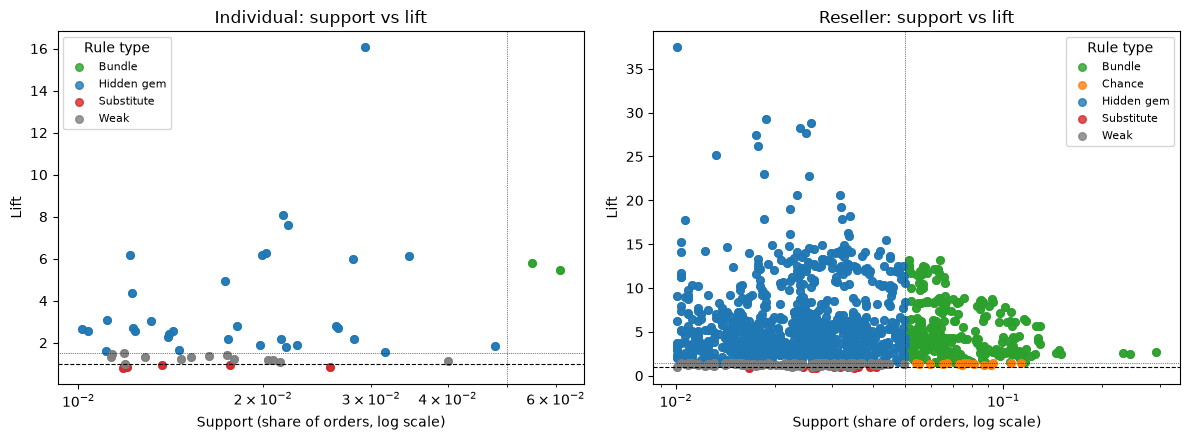

In [21]:
colors = {"Bundle": "tab:green", "Hidden gem": "tab:blue", "Chance": "tab:orange",
          "Substitute": "tab:red", "Weak": "tab:gray"}

fig, axes = plt.subplots(1, len(reviewed) or 1, figsize=(6 * max(len(reviewed), 1), 4.5), squeeze=False)
for ax, (ch, r) in zip(axes[0], reviewed.items()):
    for cls, grp in r.groupby("RuleClassification"):
        ax.scatter(grp["Support"], grp["Lift"], s=30, alpha=0.8, label=cls, color=colors.get(cls))
    ax.axhline(1, color="black", lw=0.8, ls="--")
    ax.axhline(LIFT_STRONG, color="black", lw=0.5, ls=":")
    ax.axvline(SUPPORT_BUNDLE, color="black", lw=0.5, ls=":")
    ax.set_xscale("log")
    ax.set_xlabel("Support (share of orders, log scale)")
    ax.set_ylabel("Lift")
    ax.set_title(f"{ch}: support vs lift")
    ax.legend(title="Rule type", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Write the rules to the warehouse
With `KEEP_HISTORY = False`, the channel's previous rules are replaced inside one transaction. Set it to `True` to keep earlier runs and compare them by `GeneratedDate` (then filter the dashboard to the latest run).

In [22]:
def write_rules(channel, rules):
    with engine.begin() as conn:
        if not KEEP_HISTORY:
            conn.execute(text("DELETE FROM dw.AssociationRulesFact WHERE Channel = :ch"), {"ch": channel})
        rules.to_sql("AssociationRulesFact", conn, schema="dw", if_exists="append",
                     index=False, chunksize=500)


for ch, r in results.items():
    if r["rules"].empty:
        print(f"{ch}: nothing to write.")
        continue
    write_rules(ch, r["rules"])
    print(f"{ch}: wrote {len(r['rules'])} rules to dw.AssociationRulesFact")

check = pd.read_sql(text("""
    SELECT Channel, RuleClassification, COUNT(*) AS Rules, MAX(GeneratedDate) AS LastRun
    FROM dw.AssociationRulesFact
    GROUP BY Channel, RuleClassification
    ORDER BY Channel, RuleClassification
"""), engine)
display(check)

Individual: wrote 106 rules to dw.AssociationRulesFact
Reseller: wrote 2836 rules to dw.AssociationRulesFact


,Channel,RuleClassification,Rules,LastRun
0,Individual,Bundle,4,2026-10-16 09:33:12
1,Individual,Hidden gem,64,2026-10-16 09:33:12
2,Individual,Substitute,10,2026-10-16 09:33:12
3,Individual,Weak,28,2026-10-16 09:33:12
4,Reseller,Bundle,506,2026-10-16 09:33:12
5,Reseller,Chance,30,2026-10-16 09:33:12
6,Reseller,Hidden gem,2026,2026-10-16 09:33:12
7,Reseller,Substitute,26,2026-10-16 09:33:12
8,Reseller,Weak,248,2026-10-16 09:33:12


## 7. Individual vs reseller comparison
A rule in both runs is robust. A rule only in the individual run is consumer behaviour (good for a bundle). A rule only in the reseller run is probably restocking. Support is relative to each run's own population, so compare lift and the pair, not raw support.

In [23]:
stored = pd.read_sql(text("""
    SELECT Channel, AntecedentModelID, ConsequentModelID, AntecedentModelName, ConsequentModelName,
           Support, Confidence, Lift, CoOccurrenceCount, RuleClassification, GeneratedDate
    FROM dw.AssociationRulesFact
"""), engine)

if KEEP_HISTORY and len(stored):
    latest = stored.groupby("Channel")["GeneratedDate"].transform("max")
    stored = stored[stored["GeneratedDate"] == latest]

key = ["AntecedentModelID", "ConsequentModelID"]
ind = stored[stored["Channel"] == "Individual"].drop(columns="Channel")
res = stored[stored["Channel"] == "Reseller"].drop(columns="Channel")

cmp = ind.merge(res, on=key, how="outer", suffixes=("_ind", "_res"), indicator=True)
cmp["Appears in"] = cmp["_merge"].map({"both": "both channels", "left_only": "Individual only", "right_only": "Reseller only"})
cmp["AntecedentModelName"] = cmp["AntecedentModelName_ind"].fillna(cmp["AntecedentModelName_res"])
cmp["ConsequentModelName"] = cmp["ConsequentModelName_ind"].fillna(cmp["ConsequentModelName_res"])

display(cmp["Appears in"].value_counts().rename("rules").to_frame())
display(cmp.loc[cmp["Appears in"] == "both channels",
                ["AntecedentModelName", "ConsequentModelName", "Lift_ind", "Lift_res",
                 "Support_ind", "Support_res", "RuleClassification_ind", "RuleClassification_res"]]
        .sort_values("Lift_ind", ascending=False).head(15))

,rules
Appears in,
Reseller only,2798
Individual only,68
both channels,38


,AntecedentModelName,ConsequentModelName,Lift_ind,Lift_res,Support_ind,Support_res,RuleClassification_ind,RuleClassification_res
83,Cycling Cap,Short-Sleeve Classic Jersey,2.686211,2.403322,0.012271,0.114833,Hidden gem,Bundle
1064,Short-Sleeve Classic Jersey,Cycling Cap,2.686211,2.403322,0.012271,0.114833,Hidden gem,Bundle
2725,Bike Wash,Patch kit,2.678415,7.267903,0.010116,0.034822,Hidden gem,Hidden gem
2548,Patch kit,Bike Wash,2.678415,7.267903,0.010116,0.034822,Hidden gem,Hidden gem
2438,Hydration Pack,Water Bottle,2.566300,8.096018,0.010372,0.085327,Hidden gem,Bundle
2491,Water Bottle,Hydration Pack,2.566300,8.096018,0.010372,0.085327,Hidden gem,Bundle
2463,Water Bottle,Road-750,2.186877,3.471429,0.017530,0.043062,Hidden gem,Hidden gem
1058,Road-750,Water Bottle,2.186877,3.471429,0.017530,0.043062,Hidden gem,Hidden gem
1213,Touring-1000,Sport-100,1.877577,0.878905,0.019758,0.026847,Hidden gem,Substitute
1149,Sport-100,Touring-1000,1.877577,0.878905,0.019758,0.026847,Hidden gem,Substitute


## 8. Use-case sizing for individual rules
Turns the individual rules into a decision: which rule can add profit, and how sure is that? Everything here beyond the counts is an **assumption, not a forecast**: the conversion rate (share of customers who buy B after being offered it) and the bundle discount are inputs you choose in the next cell.

For a rule {A} → {B}, with A as the trigger and B as the offer:
- **Reachable orders** = orders that contain A but not B (`support(A) × orders − co-occurrence count`).
- **Extra B sales** = reachable orders × conversion rate.
- **Margin per extra sale** = B's average line margin (revenue minus the standard cost in force on the order date) minus the discount given.
- **Leakage** = the discount also given to customers who already buy A and B together (assumed to take the offer).
- **Net profit** = extra sales × margin per sale − leakage; **break-even conversion** is the rate at which net profit is zero. If it is above what is realistic, the bundle loses money.

Association is not causation, so the real test would be a pilot with a control group.

In [24]:
PROJECTION = {
    "conversion": {"low": 0.02, "base": 0.05, "high": 0.10},   # assumed share of reachable orders that add B
    "discounts":  [0.0, 0.05, 0.10],                           # bundle discounts on B to compare
    "discount":   0.10,                                        # discount used for the ranking
}
USE_CASE = ("Road-750", "Road Bottle Cage")    # (trigger model A, offered model B), names exactly as in the rules table

MODEL_SQL = text("""
    SELECT p.ProductModelID,
           MAX(p.CategoryName)    AS CategoryName,
           MAX(p.SubcategoryName) AS SubcategoryName,
           MAX(CASE WHEN p.IsCurrent = 1 AND p.SellEndDate IS NULL THEN 1 ELSE 0 END) AS StillOnSale
    FROM dw.ProductDim AS p
    GROUP BY p.ProductModelID
""")

ECON_SQL = text("""
    SELECT p.ProductModelID,
           COUNT(*)         AS Lines,
           AVG(f.LineTotal) AS AvgLineRevenue,
           AVG(f.LineTotal - f.OrderQty * p.StandardCost) AS AvgLineMargin
    FROM dw.OrderLineFact AS f
    JOIN dw.CustomerDim   AS c ON c.CustomerKey = f.CustomerKey
    JOIN dw.ProductDim    AS p ON p.ProductKey  = f.ProductKey
    WHERE c.CustomerType = 'Individual' AND f.OrderQty > 0 AND f.UnitPrice > 0
    GROUP BY p.ProductModelID
""")

model_attr = pd.read_sql(MODEL_SQL, engine).merge(pd.read_sql(ECON_SQL, engine), on="ProductModelID", how="left")
for col in ("AvgLineRevenue", "AvgLineMargin"):
    model_attr[col] = pd.to_numeric(model_attr[col])
model_attr = model_attr.set_index("ProductModelID")


def attach_attrs(rules):
    """Add category, still-on-sale and same-category flags to a rules table."""
    r = rules.copy()
    for side in ("Antecedent", "Consequent"):
        ids = r[f"{side}ModelID"]
        r[f"{side}Category"]    = ids.map(model_attr["CategoryName"])
        r[f"{side}Subcategory"] = ids.map(model_attr["SubcategoryName"])
        r[f"{side}OnSale"]      = ids.map(model_attr["StillOnSale"]).fillna(0).astype(int).astype(bool)
    r["SameCategory"]    = r["AntecedentCategory"] == r["ConsequentCategory"]
    r["SameSubcategory"] = r["AntecedentSubcategory"] == r["ConsequentSubcategory"]
    r["BothOnSale"]      = r["AntecedentOnSale"] & r["ConsequentOnSale"]
    return r


def size_opportunity(rules, n_orders, discount):
    """Reachable orders, B economics and net profit per conversion scenario for each rule."""
    r = attach_attrs(rules)
    r["OrdersWithA"]     = (r["AntecedentSupport"] * n_orders).round().astype(int)
    r["OrdersAWithoutB"] = r["OrdersWithA"] - r["CoOccurrenceCount"]
    r["BAvgRevenue"]     = r["ConsequentModelID"].map(model_attr["AvgLineRevenue"])
    r["BAvgMargin"]      = r["ConsequentModelID"].map(model_attr["AvgLineMargin"])
    margin_after = r["BAvgMargin"] - discount * r["BAvgRevenue"]
    leakage = r["CoOccurrenceCount"] * discount * r["BAvgRevenue"]
    for name, cv in PROJECTION["conversion"].items():
        r[f"NetProfit_{name}"] = r["OrdersAWithoutB"] * cv * margin_after - leakage
    breakeven = leakage / (r["OrdersAWithoutB"] * margin_after)
    r["BreakEvenConversion"] = breakeven.where(margin_after > 0).replace([np.inf, -np.inf], np.nan)
    return r


# How much of each channel's rule set is "same product family"? (tests the restocking idea for resellers)
shape = {}
for ch, res in results.items():
    if res["rules"].empty:
        continue
    a = attach_attrs(res["rules"])
    shape[ch] = {"rules": len(a),
                 "share same subcategory": round(a["SameSubcategory"].mean(), 3),
                 "share same category": round(a["SameCategory"].mean(), 3),
                 "share with both models still on sale": round(a["BothOnSale"].mean(), 3)}
display(pd.DataFrame(shape))

,Individual,Reseller
rules,106.000,2836.000
share same subcategory,0.302,0.047
share same category,0.585,0.321
share with both models still on sale,1.000,0.683


In [25]:
n_ind = results["Individual"]["stats"]["orders with a valid line (support base)"]
sized = size_opportunity(reviewed["Individual"], n_ind, PROJECTION["discount"])

cand = sized[sized["CrossSellCandidate"] | sized["DiscountedBundleCandidate"]]
rank_cols = ["AntecedentModelName", "ConsequentModelName", "AntecedentCategory", "ConsequentCategory",
             "BothOnSale", "Support", "Confidence", "Lift", "CoOccurrenceCount", "OrdersAWithoutB",
             "BAvgRevenue", "BAvgMargin", "NetProfit_base", "BreakEvenConversion"]
print(f"Individual candidates ranked by base-case net profit "
      f"(conversion {PROJECTION['conversion']['base']:.0%}, discount {PROJECTION['discount']:.0%}); models still on sale first")
display(cand.sort_values(["BothOnSale", "NetProfit_base"], ascending=False)[rank_cols].head(15).round(3))

Individual candidates ranked by base-case net profit (conversion 5%, discount 10%); models still on sale first


,AntecedentModelName,ConsequentModelName,AntecedentCategory,ConsequentCategory,BothOnSale,Support,Confidence,Lift,CoOccurrenceCount,OrdersAWithoutB,BAvgRevenue,BAvgMargin,NetProfit_base,BreakEvenConversion
20,Mountain Tire Tube,LL Mountain Tire,Accessories,Accessories,True,0.017,0.155,4.953,474,2584,24.99,15.644,513.769,0.035
9,Road Tire Tube,LL Road Tire,Accessories,Accessories,True,0.020,0.232,6.177,546,1806,21.49,13.453,-152.630,0.057
8,LL Road Tire,Road Tire Tube,Accessories,Accessories,True,0.020,0.531,6.177,546,483,3.99,2.498,-167.170,0.215
21,LL Mountain Tire,Mountain Tire Tube,Accessories,Accessories,True,0.017,0.553,4.953,474,383,4.99,3.124,-186.263,0.235
4,ML Road Tire,Road Tire Tube,Accessories,Accessories,True,0.022,0.653,7.601,602,320,3.99,2.498,-206.619,0.358
2,HL Road Tire,Road Tire Tube,Accessories,Accessories,True,0.022,0.695,8.090,590,259,3.99,2.498,-208.232,0.433
15,ML Mountain Tire,Mountain Tire Tube,Accessories,Accessories,True,0.028,0.668,5.982,767,381,4.99,3.124,-332.732,0.383
5,Road Tire Tube,ML Road Tire,Accessories,Accessories,True,0.022,0.256,7.601,602,1750,24.99,15.644,-354.237,0.065
0,Touring Tire,Touring Tire Tube,Accessories,Accessories,True,0.029,0.863,16.059,802,127,4.99,3.124,-383.531,1.201
3,Road Tire Tube,HL Road Tire,Accessories,Accessories,True,0.022,0.251,8.090,590,1762,32.60,20.408,-412.696,0.064


In [26]:
a_name, b_name = USE_CASE
pick = sized[(sized["AntecedentModelName"] == a_name) & (sized["ConsequentModelName"] == b_name)]

if pick.empty:
    print(f"No individual rule {a_name} -> {b_name}. Check the spelling against the rules table.")
else:
    row = pick.iloc[0]
    print(f"Use case: customers who buy {a_name} are offered {b_name}")
    print(f"  support {row.Support:.2%}, confidence {row.Confidence:.1%}, lift {row.Lift:.2f}, "
          f"type {row.RuleClassification}, both models still on sale: {row.BothOnSale}")
    print(f"  orders with {a_name}: {row.OrdersWithA:,}; already with {b_name}: {row.CoOccurrenceCount:,}; "
          f"reachable (without {b_name}): {row.OrdersAWithoutB:,}")
    print(f"  {b_name}: average line revenue {row.BAvgRevenue:,.2f}, average line margin {row.BAvgMargin:,.2f}")

    R, co, rev, mar = row.OrdersAWithoutB, row.CoOccurrenceCount, row.BAvgRevenue, row.BAvgMargin
    table, breakeven = {}, {}
    for d in PROJECTION["discounts"]:
        table[f"discount {d:.0%}"] = {f"{name} ({cv:.0%})": R * cv * (mar - d * rev) - co * d * rev
                                      for name, cv in PROJECTION["conversion"].items()}
        after = mar - d * rev
        breakeven[f"discount {d:.0%}"] = (co * d * rev) / (R * after) if after > 0 else float("nan")
    print("\nNet profit by discount (rows) and conversion scenario (columns):")
    display(pd.DataFrame(table).T.round(0))
    print("Break-even conversion (net profit = 0) by discount:")
    display(pd.Series(breakeven, name="break-even conversion").map(lambda v: f"{v:.1%}").to_frame())

Use case: customers who buy Road-750 are offered Road Bottle Cage
  support 2.02%, confidence 38.7%, lift 6.26, type Hidden gem, both models still on sale: True
  orders with Road-750: 1,432; already with Road Bottle Cage: 554; reachable (without Road Bottle Cage): 878
  Road Bottle Cage: average line revenue 8.99, average line margin 5.63

Net profit by discount (rows) and conversion scenario (columns):


,low (2%),base (5%),high (10%)
discount 0%,99.0,247.0,494.0
discount 5%,-158.0,-22.0,206.0
discount 10%,-415.0,-290.0,-83.0


Break-even conversion (net profit = 0) by discount:


,break-even conversion
discount 0%,0.0%
discount 5%,5.5%
discount 10%,12.0%


## 9. Sensitivity of the individual run to the thresholds
The brief's thresholds (1% support, lift 1.5, confidence 40% or 50%) stay the main analysis. This section checks how much the conclusions depend on them, instead of searching for an "optimal" setting (there is no objective to optimise in unsupervised mining).

- **Support grid:** FP-Growth is run once at the lowest support; stricter settings are exact subsets of that result, so the table is consistent.
- **Minimum orders per pair:** the smallest co-occurrence count a rule can have at each support. A higher floor means fewer chance pairs.
- **Stability:** how many of the 20 strongest rules (by lift) at the brief's 1% support are still present, and how much the top-20 list changes, at each other setting.
- **Lift × confidence grid:** how many rules pass at the brief's 1% support under other lift and confidence cut-offs.

Decide what to look at before reading the numbers: a conclusion that holds across the grid is robust; one that only holds at a single setting is not.

Individual run, 27,382 orders in the support base. Rules are counted in both directions.


,pairs,rules,smallest co-occurrence,rules with lift >= 1.5,cross-sell (conf >= 30%),cross-sell (conf >= 40%),cross-sell (conf >= 50%),brief top-20 still present,top-20 overlap with brief
min support,,,,,,,,,
0.5%,107,214,137,132,32,14,10,20/20,16/20
1.0% (brief),53,106,277,68,28,13,10,20/20,20/20
2.0%,21,42,554,32,18,10,8,16/20,16/20
3.0%,6,12,865,10,8,4,3,6/20,6/20
5.0%,2,4,1505,4,4,2,2,4/20,4/20



Rules at 1% support passing each lift and confidence cut-off:


,conf >= 30%,conf >= 40%,conf >= 50%
lift >= 1.2,33,13,10
lift >= 1.5,28,13,10
lift >= 2.0,24,10,10
lift >= 3.0,18,10,10


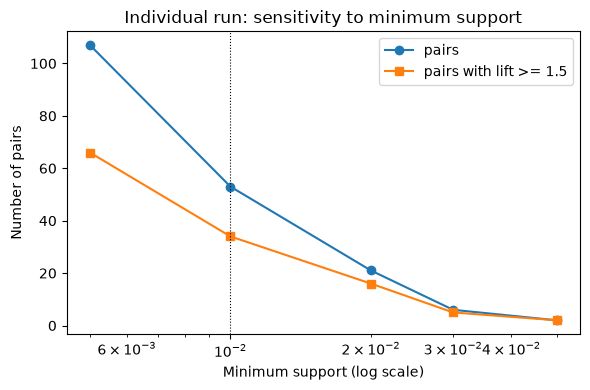

In [27]:
SENS_SUPPORT    = [0.005, 0.01, 0.02, 0.03, 0.05]
SENS_CONFIDENCE = [0.30, 0.40, 0.50]
SENS_LIFT       = [1.2, 1.5, 2.0, 3.0]
SENS_TOPK       = 20
REF_SUPPORT     = 0.01                      # the brief's setting

pairs_ind = pd.read_sql(PAIRS_SQL, engine, params={"channel": "Individual"})
basket_s = pd.crosstab(pairs_ind["SalesOrderID"], pairs_ind["ProductModelID"]).gt(0)
n_s = len(basket_s)

freq_s = fpgrowth(basket_s, min_support=min(SENS_SUPPORT), use_colnames=True, max_len=2)
try:
    raw_s = association_rules(freq_s, num_itemsets=n_s, metric="lift", min_threshold=0)
except TypeError:
    raw_s = association_rules(freq_s, metric="lift", min_threshold=0)

sens = pd.DataFrame({
    "Ant":        raw_s["antecedents"].map(lambda s: int(next(iter(s)))),
    "Con":        raw_s["consequents"].map(lambda s: int(next(iter(s)))),
    "Support":    raw_s["support"],
    "Confidence": raw_s["confidence"],
    "Lift":       raw_s["lift"],
})
sens["Count"] = (sens["Support"] * n_s).round().astype(int)


def at_support(s):
    return sens[sens["Support"] >= s - 1e-9]


def top_keys(s, k=SENS_TOPK):
    sub = at_support(s).sort_values(["Lift", "Support"], ascending=False).head(k)
    return set(zip(sub["Ant"], sub["Con"]))


ref_top = top_keys(REF_SUPPORT)
K = len(ref_top)                         # normally 20; smaller only if fewer rules exist at the brief's support
rows = []
for s in SENS_SUPPORT:
    sub = at_support(s)
    strong = sub[sub["Lift"] >= CROSS_SELL["lift"]]
    row = {"min support": f"{s:.1%}" + ("  (brief)" if abs(s - REF_SUPPORT) < 1e-9 else ""),
           "pairs": len(sub) // 2,
           "rules": len(sub),
           "smallest co-occurrence": int(sub["Count"].min()) if len(sub) else 0,
           "rules with lift >= 1.5": len(strong)}
    for c in SENS_CONFIDENCE:
        row[f"cross-sell (conf >= {c:.0%})"] = int((strong["Confidence"] >= c).sum())
    present = set(zip(sub["Ant"], sub["Con"]))
    row[f"brief top-{K} still present"] = f"{len(ref_top & present)}/{K}"
    row[f"top-{K} overlap with brief"] = f"{len(top_keys(s, K) & ref_top)}/{K}"
    rows.append(row)

sens_table = pd.DataFrame(rows).set_index("min support")
print(f"Individual run, {n_s:,} orders in the support base. Rules are counted in both directions.")
display(sens_table)

# Lift x confidence grid at the brief's support
base = at_support(REF_SUPPORT)
grid = pd.DataFrame({f"conf >= {c:.0%}": {f"lift >= {l}": int(((base["Lift"] >= l) & (base["Confidence"] >= c)).sum())
                                         for l in SENS_LIFT} for c in SENS_CONFIDENCE})
print(f"\nRules at {REF_SUPPORT:.0%} support passing each lift and confidence cut-off:")
display(grid)

# Plot: how the number of pairs and strong rules falls as the support threshold rises
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(SENS_SUPPORT, [len(at_support(s)) // 2 for s in SENS_SUPPORT], marker="o", label="pairs")
ax.plot(SENS_SUPPORT, [int((at_support(s)["Lift"] >= CROSS_SELL["lift"]).sum()) // 2 for s in SENS_SUPPORT],
        marker="s", label="pairs with lift >= 1.5")
ax.axvline(REF_SUPPORT, color="black", ls=":", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("Minimum support (log scale)")
ax.set_ylabel("Number of pairs")
ax.set_title("Individual run: sensitivity to minimum support")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Time split: do the rules found in 2011 to 2013 hold in 2014?
Mines the **individual** run on orders up to the end of 2013 (training period), then measures the same pairs on the 2014 orders (test period, January to June). A rule that keeps its lift on orders it never saw is far more trustworthy than one that only describes the period it was mined on.

- **Holds** = lift still at least 1.5 in the test period. A rule is only *judged* if it would be expected to have at least `MIN_TEST_COUNT` orders in the test period (training support × test orders). A rule that was common in training but has almost vanished in the test period therefore counts as **not holding**, not as "too few to judge".
- **Reading the result:** compare lift and confidence between the periods; support moves with volume and is not a good yardstick (individual volume grew about tenfold from 2012 to 2013).
- **Caveats:** 2014 covers only six months, and June 2014 is an atypical month (set `TEST_END = "2014-05-31"` to leave it out). A holding rule is still a co-occurrence, not proof that recommending it would change behaviour.

Training orders (to 2013-12-31): 16,363   Test orders (2014-01-01 to 2014-06-30): 11,019


,value
rules mined on the training period (support >= 1%),86.00
of which strong in training (lift >= 1.5),66.00
strong rules common enough to judge (expected test orders >= MIN_TEST_COUNT),66.00
judged strong rules with test lift >= 1.5 (hold),48.00
judged strong rules with test lift > 1,64.00
median test lift / training lift (judged strong rules),0.68
"rank correlation of lift, training vs test (all rules)",0.93
pairs frequent in training,43.00
pairs frequent in the test period (support >= 1%),63.00
pairs frequent in both,43.00


Cross-sell candidates chosen on the training period: 13; hold in the test period (lift >= 1.5, confidence >= 40%): 10
Discounted-bundle candidates chosen on the training period: 16; hold in the test period: 16

Candidates, training period vs test period:


,Rule,Support,Confidence,Lift,Count,Test support,Test confidence,Test lift,Test orders with both,Judgeable,Holds
44,Touring Tire -> Touring Tire Tube,0.023,0.856,19.843,375,0.039,0.870,12.510,427,True,True
45,Touring Tire Tube -> Touring Tire,0.023,0.531,19.843,375,0.039,0.557,12.510,427,True,True
20,HL Road Tire -> Road Tire Tube,0.020,0.687,9.300,322,0.024,0.705,6.793,268,True,True
21,Road Tire Tube -> HL Road Tire,0.020,0.267,9.300,322,0.024,0.234,6.793,268,True,True
65,Road Tire Tube -> ML Road Tire,0.018,0.243,8.601,294,0.028,0.269,6.463,308,True,True
64,ML Road Tire -> Road Tire Tube,0.018,0.635,8.601,294,0.028,0.671,6.463,308,True,True
33,HL Mountain Tire -> Mountain Tire Tube,0.030,0.688,7.135,483,0.042,0.681,5.069,465,True,True
32,Mountain Tire Tube -> HL Mountain Tire,0.030,0.306,7.135,483,0.042,0.314,5.069,465,True,True
59,Road Tire Tube -> LL Road Tire,0.017,0.224,7.128,271,0.025,0.240,5.153,275,True,True
58,LL Road Tire -> Road Tire Tube,0.017,0.526,7.128,271,0.025,0.535,5.153,275,True,True



Use-case rules, training vs test:


Rule,Mountain Tire Tube -> LL Mountain Tire,Road-750 -> Road Bottle Cage
train orders with A,1578.000,711.000
train both,237.000,280.000
train support,0.014,0.017
train confidence,0.150,0.394
train lift,5.715,7.599
test orders with A,1480.000,721.000
test both,237.000,274.000
test support,0.022,0.025
test confidence,0.160,0.380
test lift,4.132,4.962


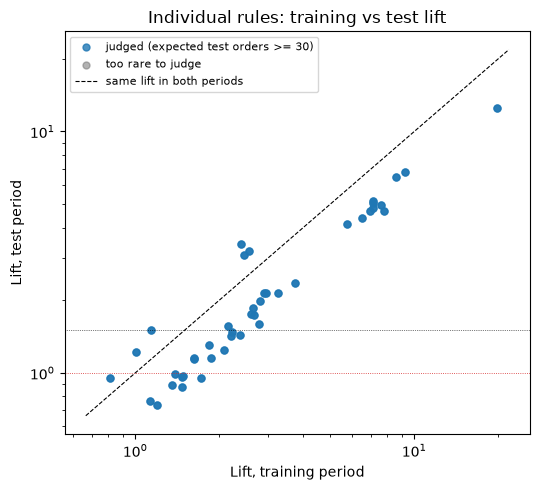

In [28]:
TRAIN_END      = "2013-12-31"
TEST_START     = "2014-01-01"
TEST_END       = "2014-06-30"       # "2014-05-31" leaves out the atypical June 2014
MIN_TEST_COUNT = 30                 # a rule is judged only if it would be expected to have at least this many test orders
WATCH = [("Mountain Tire Tube", "LL Mountain Tire"), ("Road-750", "Road Bottle Cage")]   # use-case rules to inspect

PAIRS_DATED_SQL = text("""
    SELECT DISTINCT f.SalesOrderID, p.ProductModelID, d.FullDate
    FROM dw.OrderLineFact AS f
    JOIN dw.CustomerDim   AS c ON c.CustomerKey = f.CustomerKey
    JOIN dw.ProductDim    AS p ON p.ProductKey  = f.ProductKey
    JOIN dw.DateDim       AS d ON d.DateKey     = f.DateKey
    WHERE c.CustomerType = :channel AND f.OrderQty > 0 AND f.UnitPrice > 0
""")
dated = pd.read_sql(PAIRS_DATED_SQL, engine, params={"channel": "Individual"})
dated["FullDate"] = pd.to_datetime(dated["FullDate"])
train_pairs = dated[dated["FullDate"] <= pd.Timestamp(TRAIN_END)]
test_pairs  = dated[(dated["FullDate"] >= pd.Timestamp(TEST_START)) & (dated["FullDate"] <= pd.Timestamp(TEST_END))]


def to_basket(pairs, columns=None):
    b = pd.crosstab(pairs["SalesOrderID"], pairs["ProductModelID"]).gt(0)
    return b if columns is None else b.reindex(columns=columns, fill_value=False)


def mine_pairs(basket, min_support):
    """FP-Growth pair rules (both directions) with lift, confidence and counts for one period."""
    n = len(basket)
    cols = ["Ant", "Con", "Support", "Confidence", "Lift", "Count"]
    freq = fpgrowth(basket, min_support=min_support, use_colnames=True, max_len=2)
    if not len(freq) or not (freq["itemsets"].map(len) == 2).any():
        return pd.DataFrame(columns=cols)
    try:
        raw = association_rules(freq, num_itemsets=n, metric="lift", min_threshold=0)
    except TypeError:
        raw = association_rules(freq, metric="lift", min_threshold=0)
    out = pd.DataFrame({"Ant": raw["antecedents"].map(lambda s: int(next(iter(s)))),
                        "Con": raw["consequents"].map(lambda s: int(next(iter(s)))),
                        "Support": raw["support"], "Confidence": raw["confidence"], "Lift": raw["lift"]})
    out["Count"] = (out["Support"] * n).round().astype(int)
    return out


def count_matrix(basket):
    m = basket.to_numpy(dtype=np.int32)
    return m.T @ m, {c: i for i, c in enumerate(basket.columns)}


def measure(a, b, basket, co, pos):
    """Support, confidence and lift of {a} -> {b} in one period (NaN when a model never occurs)."""
    n = len(basket)
    if a not in pos or b not in pos:
        return {"orders with A": 0, "orders with both": 0, "support": np.nan, "confidence": np.nan, "lift": np.nan,
                "reverse confidence": np.nan}
    na, nb, nab = int(co[pos[a], pos[a]]), int(co[pos[b], pos[b]]), int(co[pos[a], pos[b]])
    return {"orders with A": na, "orders with both": nab, "support": nab / n,
            "confidence": nab / na if na else np.nan,
            "lift": (nab / n) / ((na / n) * (nb / n)) if na and nb else np.nan,
            "reverse confidence": nab / nb if nb else np.nan}


b_train = to_basket(train_pairs)
b_test  = to_basket(test_pairs, columns=b_train.columns)       # test baskets on the training models
b_test_all = to_basket(test_pairs)                              # all test models, for the "new pairs" count
co_test, pos_test = count_matrix(b_test)
print(f"Training orders (to {TRAIN_END}): {len(b_train):,}   Test orders ({TEST_START} to {TEST_END}): {len(b_test):,}")

# Rules mined on the training period only, at the brief's support
train_rules = mine_pairs(b_train, MIN_SUPPORT["Individual"])
rev = train_rules.set_index(["Ant", "Con"])["Confidence"]
train_rules["RevConfidence"] = [rev.get((b, a), np.nan) for a, b in zip(train_rules["Ant"], train_rules["Con"])]

test_cols = [measure(a, b, b_test, co_test, pos_test) for a, b in zip(train_rules["Ant"], train_rules["Con"])]
ev = pd.concat([train_rules.reset_index(drop=True), pd.DataFrame(test_cols).add_prefix("Test ")], axis=1)
ev["Expected test orders"] = ev["Support"] * len(b_test)          # what a stable pattern would show in the test period
ev["Judgeable"] = ev["Expected test orders"] >= MIN_TEST_COUNT
ev["Holds"]    = ev["Test lift"] >= LIFT_STRONG

strong = ev[ev["Lift"] >= LIFT_STRONG]
strong_rel = strong[strong["Judgeable"]]
test_rules = mine_pairs(b_test_all, MIN_SUPPORT["Individual"])
pairs_train = set(map(frozenset, zip(train_rules["Ant"], train_rules["Con"])))
pairs_test  = set(map(frozenset, zip(test_rules["Ant"], test_rules["Con"])))

finite = ev.dropna(subset=["Lift", "Test lift"])
spearman = finite["Lift"].rank().corr(finite["Test lift"].rank()) if len(finite) > 2 else np.nan

summary = pd.Series({
    "rules mined on the training period (support >= 1%)": len(train_rules),
    "  of which strong in training (lift >= 1.5)": len(strong),
    "  strong rules common enough to judge (expected test orders >= MIN_TEST_COUNT)": len(strong_rel),
    "  judged strong rules with test lift >= 1.5 (hold)": int(strong_rel["Holds"].sum()),
    "  judged strong rules with test lift > 1": int((strong_rel["Test lift"] > 1).sum()),
    "median test lift / training lift (judged strong rules)": round(float((strong_rel["Test lift"] / strong_rel["Lift"]).median()), 2) if len(strong_rel) else np.nan,
    "rank correlation of lift, training vs test (all rules)": round(float(spearman), 2),
    "pairs frequent in training": len(pairs_train) ,
    "pairs frequent in the test period (support >= 1%)": len(pairs_test),
    "pairs frequent in both": len(pairs_train & pairs_test),
}, name="value")
display(summary.to_frame())

# Candidates as they would have been selected on the training period only
ev["CrossSell"] = ((ev["Lift"] >= CROSS_SELL["lift"]) & (ev["Support"] >= CROSS_SELL["support"])
                   & (ev["Confidence"] >= CROSS_SELL["confidence"]))
ev["DiscBundle"] = ((ev["Lift"] >= BUNDLING["lift"]) & ev["Support"].between(BUNDLING["support_min"], BUNDLING["support_max"])
                    & (ev[["Confidence", "RevConfidence"]].max(axis=1) >= BUNDLING["confidence"]))
ev["CrossSellHolds"]  = (ev["CrossSell"] & ev["Judgeable"] & ev["Holds"] & (ev["Test confidence"] >= CROSS_SELL["confidence"]))
ev["DiscBundleHolds"] = (ev["DiscBundle"] & ev["Judgeable"] & ev["Holds"]
                         & (ev[["Test confidence", "Test reverse confidence"]].max(axis=1) >= BUNDLING["confidence"]))
print(f"Cross-sell candidates chosen on the training period: {int(ev['CrossSell'].sum())}; "
      f"hold in the test period (lift >= 1.5, confidence >= {CROSS_SELL['confidence']:.0%}): {int(ev['CrossSellHolds'].sum())}")
print(f"Discounted-bundle candidates chosen on the training period: {int(ev['DiscBundle'].sum())}; "
      f"hold in the test period: {int(ev['DiscBundleHolds'].sum())}")

label = lambda mid: names.get(mid, f"Model {mid}")
show = ev[ev["CrossSell"] | ev["DiscBundle"]].copy()
show["Rule"] = [f"{label(a)} -> {label(b)}" for a, b in zip(show["Ant"], show["Con"])]
cols = ["Rule", "Support", "Confidence", "Lift", "Count", "Test support", "Test confidence", "Test lift",
        "Test orders with both", "Judgeable", "Holds"]
print("\nCandidates, training period vs test period:")
display(show.sort_values("Lift", ascending=False)[cols].head(20).round(3))

# The use-case rules, measured directly (even if they fall below 1% support in one period)
ids = {v: k for k, v in names.items()}
co_train, pos_train = count_matrix(b_train)
rows = []
for a_name, b_name in WATCH:
    a, b = ids.get(a_name), ids.get(b_name)
    if a is None or b is None:
        print(f"Unknown model name in WATCH: {a_name} / {b_name}")
        continue
    tr_m = measure(a, b, b_train, co_train, pos_train)
    te_m = measure(a, b, b_test_all, *count_matrix(b_test_all))
    rows.append({"Rule": f"{a_name} -> {b_name}",
                 "train orders with A": tr_m["orders with A"], "train both": tr_m["orders with both"],
                 "train support": tr_m["support"], "train confidence": tr_m["confidence"], "train lift": tr_m["lift"],
                 "test orders with A": te_m["orders with A"], "test both": te_m["orders with both"],
                 "test support": te_m["support"], "test confidence": te_m["confidence"], "test lift": te_m["lift"]})
if rows:
    print("\nUse-case rules, training vs test:")
    display(pd.DataFrame(rows).set_index("Rule").round(3).T)

# Plot: lift in training vs lift in test (each point is a rule)
fig, ax = plt.subplots(figsize=(5.5, 5))
ok = finite[finite["Judgeable"]]
low = finite[~finite["Judgeable"]]
ax.scatter(ok["Lift"], ok["Test lift"], s=25, alpha=0.8, label="judged (expected test orders >= " + str(MIN_TEST_COUNT) + ")")
ax.scatter(low["Lift"], low["Test lift"], s=25, alpha=0.6, color="tab:gray", label="too rare to judge")
lims = [min(finite["Lift"].min(), finite["Test lift"].min()) * 0.9, max(finite["Lift"].max(), finite["Test lift"].max()) * 1.1]
ax.plot(lims, lims, color="black", lw=0.8, ls="--", label="same lift in both periods")
ax.axhline(1, color="tab:red", lw=0.6, ls=":")
ax.axhline(LIFT_STRONG, color="black", lw=0.5, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Lift, training period"); ax.set_ylabel("Lift, test period")
ax.set_title("Individual rules: training vs test lift")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. June 2014 check
Re-runs the time split with the test period ending 31 May 2014, which leaves out June 2014 (the atypical month: volume fell about 57% from May). If the conclusions are the same, June does not drive them. Only the counts and the holding rules are compared; the training period is unchanged.

In [29]:
def test_summary(test_end):
    tp = dated[(dated["FullDate"] >= pd.Timestamp(TEST_START)) & (dated["FullDate"] <= pd.Timestamp(test_end))]
    bt = to_basket(tp, columns=b_train.columns)
    cot, post = count_matrix(bt)
    e = train_rules.copy()
    cols = [measure(a, b, bt, cot, post) for a, b in zip(e["Ant"], e["Con"])]
    e = pd.concat([e.reset_index(drop=True), pd.DataFrame(cols).add_prefix("Test ")], axis=1)
    e["Judgeable"] = (e["Support"] * len(bt)) >= MIN_TEST_COUNT
    st = e[(e["Lift"] >= LIFT_STRONG) & e["Judgeable"]]
    holds = st[st["Test lift"] >= LIFT_STRONG]
    fin = e.dropna(subset=["Lift", "Test lift"])
    return {
        "test orders": len(bt),
        "judged strong rules": len(st),
        "hold (test lift >= 1.5)": len(holds),
        "hold rate": round(len(holds) / len(st), 3) if len(st) else np.nan,
        "median test lift / training lift": round(float((st["Test lift"] / st["Lift"]).median()), 2) if len(st) else np.nan,
        "rank correlation of lift": round(float(fin["Lift"].rank().corr(fin["Test lift"].rank())), 2) if len(fin) > 2 else np.nan,
        "_holding": set(zip(holds["Ant"], holds["Con"])),
        "_cand_cross": set(zip(st[st["Test confidence"] >= CROSS_SELL["confidence"]]["Ant"],
                               st[st["Test confidence"] >= CROSS_SELL["confidence"]]["Con"])),
    }

full = test_summary(TEST_END)
no_june = test_summary("2014-05-31")
rows = {k: (full[k], no_june[k]) for k in full if not k.startswith("_")}
comp = pd.DataFrame(rows, index=["Jan to Jun 2014", "Jan to May 2014"]).T
display(comp)

same = full["_holding"] == no_june["_holding"]
print(f"Holding rules identical with and without June: {same}")
if not same:
    print("  only with June:", sorted(full["_holding"] - no_june["_holding"])[:10])
    print("  only without June:", sorted(no_june["_holding"] - full["_holding"])[:10])
print(f"Use-case rules, test lift Jan to Jun 2014 vs Jan to May 2014:")
for a_name, b_name in WATCH:
    a, b = ids.get(a_name), ids.get(b_name)
    if a is None or b is None:
        continue
    lifts = []
    for end in (TEST_END, "2014-05-31"):
        tp = dated[(dated["FullDate"] >= pd.Timestamp(TEST_START)) & (dated["FullDate"] <= pd.Timestamp(end))]
        bt = to_basket(tp, columns=b_train.columns)
        cot, post = count_matrix(bt)
        lifts.append(round(measure(a, b, bt, cot, post)["lift"], 3))
    print(f"  {a_name} -> {b_name}: {lifts[0]} (to June) vs {lifts[1]} (to May)")

,Jan to Jun 2014,Jan to May 2014
test orders,11019.000,10089.000
judged strong rules,66.000,66.000
hold (test lift >= 1.5),48.000,48.000
hold rate,0.727,0.727
median test lift / training lift,0.680,0.700
rank correlation of lift,0.930,0.930


Holding rules identical with and without June: True
Use-case rules, test lift Jan to Jun 2014 vs Jan to May 2014:
  Mountain Tire Tube -> LL Mountain Tire: 4.132 (to June) vs 4.414 (to May)
  Road-750 -> Road Bottle Cage: 4.962 (to June) vs 4.597 (to May)
